In [ ]:
from google.colab import drive
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
path_train='/content/drive/MyDrive/Classification_train.csv'
path_test='/content/drive/MyDrive/Classification_test.csv'

In [ ]:
train=pd.read_csv(path_train)
test=pd.read_csv(path_test)
train.head(30000)


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
29996,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
29997,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
29998,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
test.head(10000)

,ID,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,15795,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,860,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,5390,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,11964,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,11284,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,11260,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9996,18563,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9997,634,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9998,10057,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
train.describe()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
count,30000.000000,30000.0,30000.0,30000.0,30000.0,30000.0,30000.0,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000,30000.0,30000.0,30000.0
mean,4.498500,0.0,0.0,0.0,0.0,0.0,0.0,0.034000,0.049900,0.087733,...,0.024233,0.031767,0.03130,0.037533,0.007433,0.002767,0.007567,0.0,0.0,0.0
std,2.860875,0.0,0.0,0.0,0.0,0.0,0.0,2.944339,2.909964,4.445233,...,1.936553,2.765576,2.07814,2.465453,1.287491,0.479201,1.310585,0.0,0.0,0.0
min,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
25%,2.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
50%,4.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
75%,7.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
max,9.000000,0.0,0.0,0.0,0.0,0.0,0.0,255.000000,255.000000,255.000000,...,255.000000,255.000000,150.00000,170.000000,223.000000,83.000000,227.000000,0.0,0.0,0.0


In [ ]:


# Separating the labels and features in the training data
train_data = train.values  # Converted the training DataFrame into a NumPy array for easier calculations.
Y = train_data[:, 0].reshape(train_data.shape[0], 1)  # Grabbed the first column (labels) and reshaped it for calculations.
X = train_data[:, 1:]  # Grabbed the remaining columns (features) for the model.

# Separating the features in the test data
test_data = test.values  # Converted the test DataFrame into a NumPy array.
X_test = test_data[:, 1:]  # Grabbed the features from the test data, ignoring the first column (ID).

# Reshaping the data for the model
X = X.T  # Transposed the features matrix for easier calculations in the model.
Y = Y.reshape(1, X.shape[1])  # Reshaped the labels array to match the features matrix.
X_test = X_test.T  # Transposed the test features matrix as well.

iterations=100
learning_rate=0.000000006
epsilon=1e-15

# Defining the sigmoid function (used for making predictions)
def sigmoid(x):
    return 1 / (1 + np.exp(-x))  # Created a function that calculates the sigmoid of a number.

# Defining the main model training function
def model(X, Y, learning_rate, iterations, epsilon):
    # Initializing model parameters
    m = X.shape[1]  # Got the number of training examples.m=30000
    n = X.shape[0]  # Got the number of features.n=784
    W = np.zeros((n, 1))  # Created a matrix of weights, filled with zeros.column matrix
    B = 0  # Set the bias term to zero initially.
    cost_list = []  # Created an empty list to store the cost values for later analysis.

    # Iterations for training the model
    for i in range(iterations):
        Z = np.dot(W.T, X) + B  # Calculated a weighted sum of the features and bias.
        A = sigmoid(Z)  # Passed the weighted sum through the sigmoid function to get predictions.

        # Calculating the cost (how far off the model's predictions are)
        cost = (1 / m) * np.sum(Y * np.log(A + epsilon) + (1 - Y) * np.log(1 - A + epsilon))  # Calculated a special cost function that works well for logistic regression.

        # Updating model parameters using gradient descent
        dW = (1 / m) * np.dot(A - Y, X.T)  # Calculated the gradient of the cost function with respect to the weights.
        dB = (1 / m) * np.sum(A - Y)  # Calculated the gradient of the cost function with respect to the bias.
        W = W - learning_rate * dW.T  # Updated the weights by adjusting them in the opposite direction of the gradient.
        B = B - learning_rate * dB  # Updated the bias in the same way.

        # Keeping track of the cost for analysis
        cost_list.append(cost)  # Added the cost to the list for later plotting.

# Print the cost every 10% of the iterations to see how the model is learning
        if (i % (iterations/10)) == 0:
            print("Cost after", i, "iterations is", -cost)  # Showed a quick update on how well the model was doing during training.

# Return the final weights, bias, and cost list for further analysis
    return W, B, cost_list  # Sent back the model's final values and a record of how the cost changed during training.

# Define a function to train multiple models for multi-class classification
def one_vs_all(X, Y, num_classes, learning_rate, iterations, epsilon):
    # Create an empty list to store all the trained models
    models = []  # Made a place to keep each model we'd train.

    # Loop through each class and train a separate model for it
    for class_label in range(num_classes):
        # Convert the labels to 1 for the current class and 0 for others
        binary_Y = np.where(Y == class_label, 1, 0)  # Focused the model on one class at a time by changing the labels.
#The np.where function is used here to create a binary representation of the labels
        # Train a model for this class
        W, B, _ = model(X, binary_Y, learning_rate, iterations, epsilon)  # Trained a model specifically for this class.

        # Add the trained model to the list
        models.append((W, B))  # Stored the model away for later use.

    # Return all the trained models
    return models  # Gave back all the models so we could use them to make predictions.

# Define a function to make predictions on new data using the trained models
def predict_multiclass(X, models):
    # Get predictions from all models for each data point
    all_predictions = np.array([predict(X, W, B) for W, B in models])  # Asked each model for its prediction on each data point.

    # Choose the class with the highest predicted probability
    predicted_classes = np.argmax(all_predictions, axis=0)  # Picked the class with the most votes from the models.

    # Return the predicted classes
    return predicted_classes  # Gave back the final predictions for all the data points.

# Define a function to make predictions using a single model
def predict(X, W, B):
    # Calculate the weighted sum of features and bias
    Z = np.dot(W.T, X) + B  # Combined the features with the model's weights and bias.

    # Apply the sigmoid function to get probabilities
    A = sigmoid(Z)  # Transformed the weighted sum into probabilities between 0 and 1.

    # Return the probabilities (no rounding for multi-class)
    return A  # Sent back the probabilities without rounding, as we'd need them for later comparisons.

# Train models for 10 classes (assuming there are 10 classes in the data)
num_classes = 10  # Told the code how many different classes we were trying to predict.

models = one_vs_all(X, Y.ravel(), num_classes, learning_rate, iterations, epsilon)  # Trained a model for each class.

# Make predictions on the training set to see how well the models learned
Y_pred = predict_multiclass(X, models)  # Used the models to predict the classes for the data they were trained on.
accuracy = np.mean(Y_pred == Y.ravel()) * 100  # Calculated how often the predictions matched the true classes.
print("Accuracy on training set:", accuracy, "%")  # Showed how well the models did on the data they already saw.

# Make predictions on the test set to evaluate performance on unseen data
Y_pred_test = predict_multiclass(X_test, models)  # Used the models to predict classes for brand new data they hadn't seen before.
#""""output comes 10 times because ,, there are 10 classes..""""

Cost after 0 iterations is 0.6931471805599435
Cost after 10 iterations is 0.6852219687287883
Cost after 20 iterations is 0.6775072423441814
Cost after 30 iterations is 0.6699971200972894
Cost after 40 iterations is 0.6626858404494147
Cost after 50 iterations is 0.655567764103332
Cost after 60 iterations is 0.6486373759355828
Cost after 70 iterations is 0.6418892864278344
Cost after 80 iterations is 0.6353182326348045
Cost after 90 iterations is 0.6289190787253864
Cost after 0 iterations is 0.6931471805599435
Cost after 10 iterations is 0.6842354158406224
Cost after 20 iterations is 0.6755633668805209
Cost after 30 iterations is 0.667124306064362
Cost after 40 iterations is 0.6589116359051232
Cost after 50 iterations is 0.650918893061271
Cost after 60 iterations is 0.6431397516265333
Cost after 70 iterations is 0.6355680257404905
Cost after 80 iterations is 0.6281976715680908
Cost after 90 iterations is 0.6210227886955736
Cost after 0 iterations is 0.6931471805599435
Cost after 10 itera

Cost after 0 iterations is 0.6931471805599435
Cost after 10 iterations is 0.6852219687287883
Cost after 20 iterations is 0.6775072423441814
Cost after 30 iterations is 0.6699971200972894
Cost after 40 iterations is 0.6626858404494147
Cost after 50 iterations is 0.655567764103332
Cost after 60 iterations is 0.6486373759355828
Cost after 70 iterations is 0.6418892864278344
Cost after 80 iterations is 0.6353182326348045
Cost after 90 iterations is 0.6289190787253864
Cost after 0 iterations is 0.6931471805599435
Cost after 10 iterations is 0.6842354158406224
Cost after 20 iterations is 0.6755633668805209
Cost after 30 iterations is 0.667124306064362
Cost after 40 iterations is 0.6589116359051232
Cost after 50 iterations is 0.650918893061271
Cost after 60 iterations is 0.6431397516265333
Cost after 70 iterations is 0.6355680257404905
Cost after 80 iterations is 0.6281976715680908
Cost after 90 iterations is 0.6210227886955736
Cost after 0 iterations is 0.6931471805599435
Cost after 10 itera

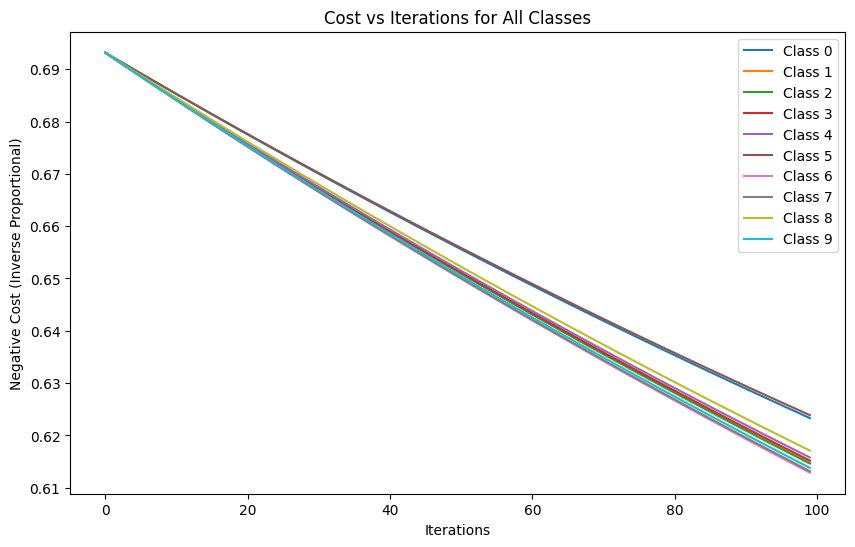

In [ ]:
import matplotlib.pyplot as plt
num_classes=10
# Plotting Cost vs Iterations for all classes
plt.figure(figsize=(10, 6))
for class_label in range(num_classes):
    _, _, cost_list = model(X, np.where(Y == class_label, 1, 0), learning_rate, iterations, epsilon)
    plt.plot(range(iterations), [-cost for cost in cost_list], label=f'Class {class_label}')

plt.title('Cost vs Iterations for All Classes')
plt.xlabel('Iterations')
plt.ylabel('Negative Cost (Inverse Proportional)')
plt.legend()
plt.show()


In [ ]:
Y_pred


array([[0, 8, 1, ..., 9, 3, 5]])

In [ ]:
Y

array([[0, 8, 1, ..., 9, 3, 9]])

In [ ]:
Y_pred_test

array([[0, 4, 5, ..., 0, 8, 5]])

In [ ]:
Y_pred_test.shape

(1, 10000)